# Butterfly Species Classification: Part 1 (Data + CNN from scratch)
### Local version for Mac (PyTorch, Apple GPU)

## 1. Introduction

Run the cells from top to bottom. Each cell does one small job.

**Saving progress:** every trained model is saved in a folder called `checkpoints`. If your computer restarts or the notebook crashes, just run the cells again from the top. Models that are already trained are loaded from disk instead of retrained. (To retrain a model on purpose, delete its files from the `checkpoints` folder.)

## 2. Setup

In [1]:
import sys
print(sys.executable)

/Users/nghitran/butterfly/venv/bin/python


In [327]:
import os
import json
import random
import shutil
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from torchvision.transforms import v2

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Fixed seeds so the results are (mostly) repeatable
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use Mac's GPU ("mps") if it is available, otherwise the CPU
if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Using device:", device) 

# Folder where trained models will be saved
os.makedirs("checkpoints", exist_ok=True)

Using device: mps


## 3. Point to the dataset

Download the zip from the Kaggle page in your browser, unzip it, and put the path to the unzipped folder below. The folder should contain `train`, `valid` and `test`.

In [9]:
# establish path to downloaded files
data_path = os.path.expanduser("~/Downloads/archive")

print(os.listdir(data_path))

['valid', 'test', 'training.csv.csv', 'butterflies and moths.csv', 'EfficientNetB0-100-(224 X 224)- 97.59.h5', 'train']


In [13]:
# Paths to the three folders that come with the dataset
train_dir = os.path.join(data_path, "train")
valid_dir = os.path.join(data_path, "valid")
test_dir = os.path.join(data_path, "test")

## 4. Dataset exploration

In [15]:
# Class names = the folder names inside the train folder
class_names = sorted(os.listdir(train_dir))
class_names = [name for name in class_names if os.path.isdir(os.path.join(train_dir, name))]
num_classes = len(class_names)
print("Number of classes:", num_classes)
print("First 5 classes:", class_names[:5])

Number of classes: 100
First 5 classes: ['ADONIS', 'AFRICAN GIANT SWALLOWTAIL', 'AMERICAN SNOOT', 'AN 88', 'APPOLLO']


In [17]:
# Count how many images are in each folder of the ORIGINAL dataset
def count_images(folder):
    total = 0
    for class_name in class_names:
        total = total + len(os.listdir(os.path.join(folder, class_name)))
    return total

print("Original train images:     ", count_images(train_dir))
print("Original validation images:", count_images(valid_dir))
print("Original test images:      ", count_images(test_dir))

Original train images:      12594
Original validation images: 500
Original test images:       500


Fewest images in a class: 100
Most images in a class:   187


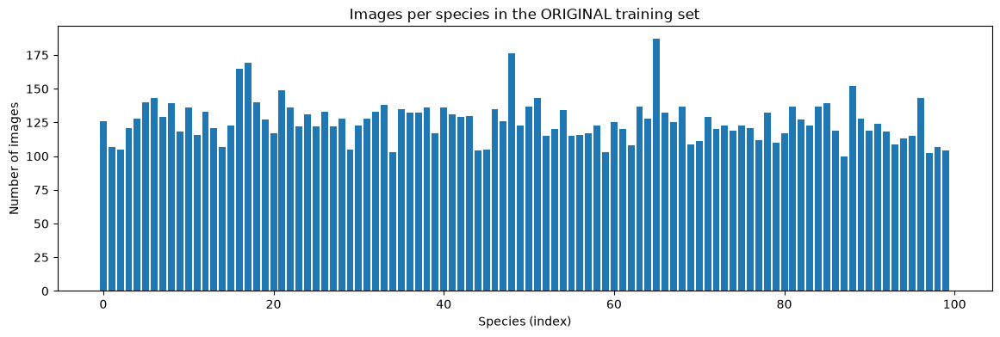

In [19]:
# Is the original training set balanced? (one bar per species)
original_counts = []
for class_name in class_names:
    n = len(os.listdir(os.path.join(train_dir, class_name)))
    original_counts.append(n)

print("Fewest images in a class:", min(original_counts))
print("Most images in a class:  ", max(original_counts))

plt.figure(figsize=(14, 4))
plt.bar(range(num_classes), original_counts)
plt.title("Images per species in the ORIGINAL training set")
plt.xlabel("Species (index)")
plt.ylabel("Number of images")
plt.show()

### Build the small training subset (20 images per species)

We take **20 random training images per species**.
We keep the dataset's own validation and test folders as they are, so the test set stays meaningful.

In [21]:
images_per_class = 20
subset_root = "butterfly_20subset"
subset_dir = os.path.join(subset_root, "train")

random.seed(SEED)   # same 20 images every time we run this cell

# Start fresh if we already made a subset before
if os.path.exists(subset_root):
    shutil.rmtree(subset_root)

for class_name in class_names:
    source_folder = os.path.join(train_dir, class_name)

    # only keep real image files
    all_files = []
    for file_name in sorted(os.listdir(source_folder)):
        if file_name.lower().endswith((".jpg", ".jpeg", ".png")):
            all_files.append(file_name)

    chosen_files = random.sample(all_files, images_per_class)

    new_folder = os.path.join(subset_dir, class_name)
    os.makedirs(new_folder)

    for file_name in chosen_files:
        old_path = os.path.join(source_folder, file_name)
        new_path = os.path.join(new_folder, file_name)
        shutil.copy(old_path, new_path)

print("Subset created!")
print("Training images used:  ", num_classes * images_per_class)
print("Validation images used:", count_images(valid_dir))
print("Test images used:      ", count_images(test_dir))

Subset created!
Training images used:   2000
Validation images used: 500
Test images used:       500


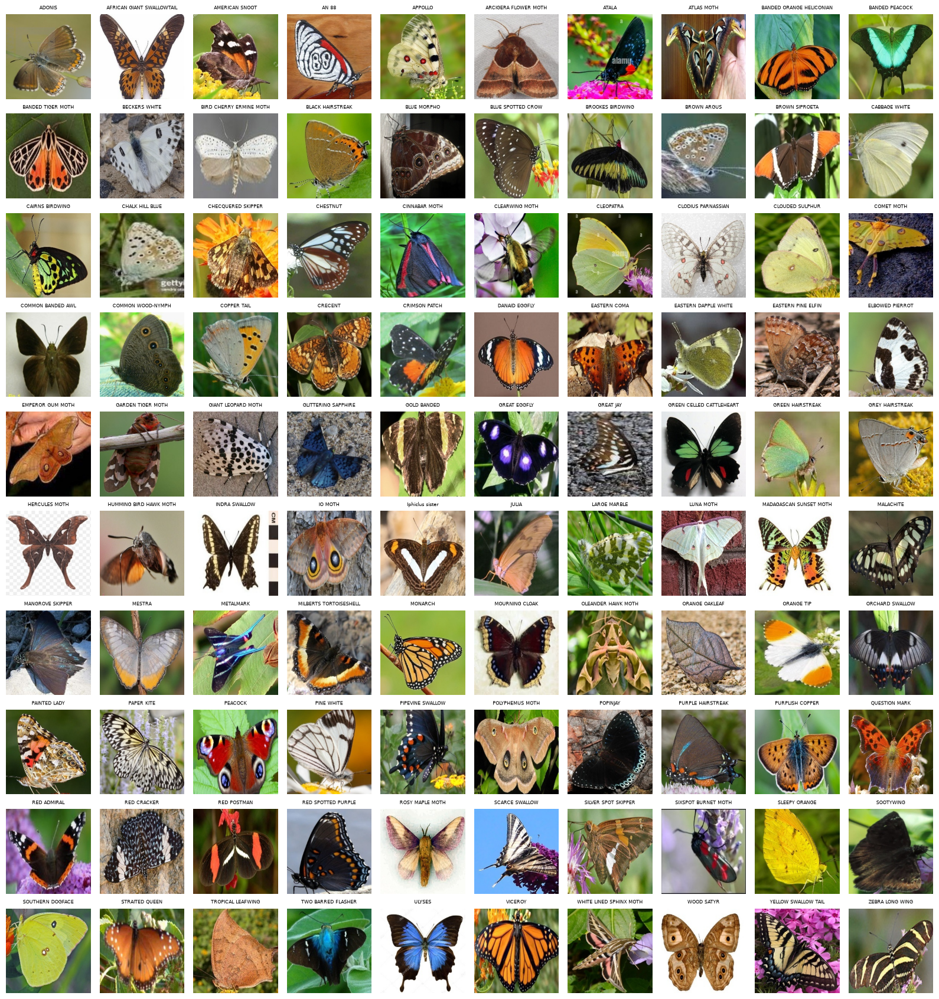

In [23]:
# One sample image from every species
columns = 10
rows = (num_classes + columns - 1) // columns

fig, axes = plt.subplots(rows, columns, figsize=(16, 1.7 * rows))
axes = axes.flatten()

for ax in axes:
    ax.axis("off")

for i, class_name in enumerate(class_names):
    folder = os.path.join(subset_dir, class_name)
    first_file = sorted(os.listdir(folder))[0]
    image = plt.imread(os.path.join(folder, first_file))
    axes[i].imshow(image)
    axes[i].set_title(class_name, fontsize=6)

plt.tight_layout()
plt.show()

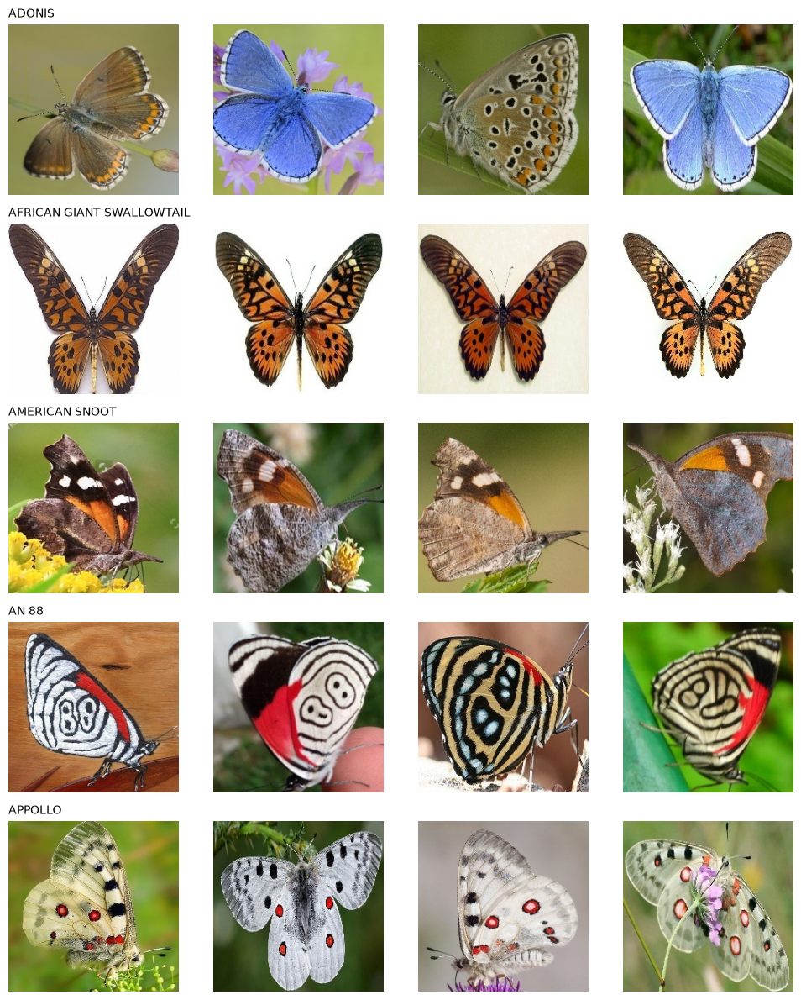

In [25]:
# Several images from a few species 
start = 0
classes_to_show = class_names[start:start + 5]

fig, axes = plt.subplots(len(classes_to_show), 4, figsize=(10, 12))

for row, class_name in enumerate(classes_to_show):
    folder = os.path.join(subset_dir, class_name)
    files = sorted(os.listdir(folder))[:4]
    for col, file_name in enumerate(files):
        image = plt.imread(os.path.join(folder, file_name))
        axes[row][col].imshow(image)
        axes[row][col].axis("off")
        if col == 0:
            axes[row][col].set_title(class_name, fontsize=10, loc="left")

plt.tight_layout()
plt.show()

## 5. Preprocessing steps

1. **Split:** train = 20 per species, validation and test = the dataset's own folders.
2. **Resize:** every image becomes 128 x 128 pixels (so the CNN gets a fixed input size).
3. **Normalization:** divide pixel values by 255 so they go from 0-255 to 0-1.
4. **Data augmentation:** random flips, rotations and zooms on training images only.

In [31]:
IMG_SIZE = 224

# Resize each picture and turn it into numbers (pixel values 0-255)
resize_and_convert = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)),
                                         transforms.PILToTensor(),])

def load_folder(folder):
    # Reads every image in the folder once and stacks them into one big tensor
    dataset = datasets.ImageFolder(folder, transform=resize_and_convert)
    images = torch.stack([dataset[i][0] for i in range(len(dataset))])
    labels = torch.tensor(dataset.targets)
    return images, labels, dataset.classes

train_images, train_labels, train_classes = load_folder(subset_dir)
val_images, val_labels, val_classes = load_folder(valid_dir)
test_images, test_labels, test_classes = load_folder(test_dir)

# Make sure all three folders use the same class order
assert train_classes == val_classes == test_classes == class_names

print("Train:     ", train_images.shape)
print("Validation:", val_images.shape)
print("Test:      ", test_images.shape)

Train:      torch.Size([2000, 3, 224, 224])
Validation: torch.Size([500, 3, 224, 224])
Test:       torch.Size([500, 3, 224, 224])


In [43]:
# A small helper that hands out one image at a time (optionally augmented)
class ImageData(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = self.images[index]
        if self.transform is not None:
            image = self.transform(image)
        return image.float(), self.labels[index]


# Data augmentation: random flip, small rotation, small zoom, small translation, slight lighting difference
augmentation = v2.Compose([
    v2.ToDtype(torch.float32, scale=True), #0-255 -> 0-1
    v2.RandomHorizontalFlip(),
    v2.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    v2.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.02)
])

BATCH_SIZE = 32

# Training without augmentation (used for CNN v1 and v2)
train_loader_plain = DataLoader(ImageData(train_images, train_labels), batch_size=BATCH_SIZE, shuffle=True)

# Training WITH augmentation (used for CNN v3 and v4)
train_loader_aug = DataLoader(ImageData(train_images, train_labels, augmentation), batch_size=BATCH_SIZE, shuffle=True)

# Used only to measure training accuracy at the end (no shuffling, no augmentation)
train_loader_eval = DataLoader(ImageData(train_images, train_labels), batch_size=BATCH_SIZE, shuffle=False)

# Validation and test (no shuffling, no augmentation)
val_loader = DataLoader(ImageData(val_images, val_labels), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(ImageData(test_images, test_labels), batch_size=BATCH_SIZE, shuffle=False)

In [84]:
images, labels = next(iter(train_loader_plain))

print("Data type:", images.dtype)
print("Minimum:", images.min().item())
print("Maximum:", images.max().item())
print("Shape:", images.shape)

Data type: torch.float32
Minimum: 0.0
Maximum: 255.0
Shape: torch.Size([32, 3, 224, 224])


In [45]:
# What does normalization do to the pixel values?
images, labels = next(iter(train_loader_plain))
print("One batch of images has shape:", images.shape)
print("Pixel values BEFORE normalization: min =", images.min().item(), " max =", images.max().item())

normalized = images / 255.0
print("Pixel values AFTER normalization:  min =", normalized.min().item(), " max =", normalized.max().item())

One batch of images has shape: torch.Size([32, 3, 224, 224])
Pixel values BEFORE normalization: min = 0.0  max = 255.0
Pixel values AFTER normalization:  min = 0.0  max = 1.0


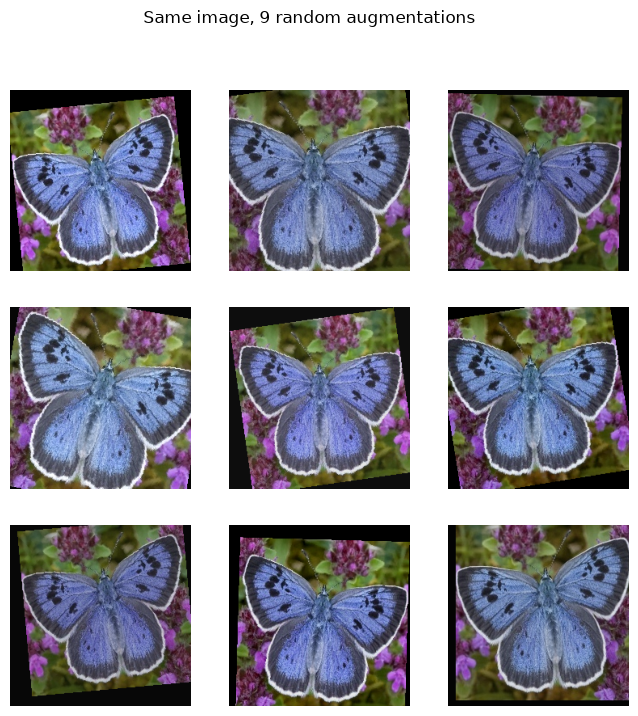

In [55]:
# Take one image and show 9 random augmented versions of it
one_image = train_images[7]

plt.figure(figsize=(8, 8))
for i in range(9):
    augmented = augmentation(one_image)
    plt.subplot(3, 3, i + 1)
    plt.imshow(augmented.permute(1, 2, 0).numpy())
    plt.axis("off")
plt.suptitle("Same image, 9 random augmentations")
plt.show()

## 6. Helper functions

These functions are used for every model, so we write them once.

In [57]:
# Evaluate a model on a dataset: returns loss, accuracy, true labels, predicted labels

def evaluate_loader(model, loader):
    model.eval()
    loss_function = nn.CrossEntropyLoss(reduction="sum")

    total_loss = 0
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            total_loss = total_loss + loss_function(outputs, labels).item()

            all_predictions.append(outputs.argmax(dim=1).cpu())
            all_labels.append(labels.cpu())

    predictions = torch.cat(all_predictions).numpy()
    true_labels = torch.cat(all_labels).numpy()

    loss = total_loss / len(true_labels)
    accuracy = (predictions == true_labels).mean()
    return loss, accuracy, true_labels, predictions

In [197]:
# Train a model. Saves the best version to the "checkpoints" folder.
# If a saved version already exists, it is loaded instead of training again.
def train_model(model, name, train_loader, epochs=30):
    weights_file = os.path.join("checkpoints", name + ".pt")
    history_file = os.path.join("checkpoints", name + "_history.json")

    model.to(device)

    # Already trained before? Load it and skip training.
    if os.path.exists(weights_file) and os.path.exists(history_file):
        print("Found a saved model for", name, "- loading it (no training needed).")
        model.load_state_dict(torch.load(weights_file, map_location=device))
        with open(history_file) as file:
            history = json.load(file)
        return history

    loss_function = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": [],
              "training_time_min": None}
    best_val_loss = float("inf")
    epoch_times = []

    #start total timer
    if device.type == "mps":
        torch.mps.synchronize()

    total_start = time.time()

    for epoch in range(epochs):

        #Start epoch timer
        if device.type == "mps":
            torch.mps.synchronize()

        epoch_start = time.time()

        #training pass
        model.train()
        total_loss = 0
        total_correct = 0
        total_images = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_function(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss = total_loss + loss.item() * len(labels)
            total_correct = total_correct + (outputs.argmax(dim=1) == labels).sum().item()
            total_images = total_images + len(labels)

        train_loss = total_loss / total_images

        #Evaluate on clean train images 
        train_loss, train_accuracy, _, _ = evaluate_loader(model, train_loader_eval)

        # evaluate on clean valid images
        val_loss, val_accuracy, _, _ = evaluate_loader(model, val_loader)
        
        #save work
        history["loss"].append(train_loss)
        history["accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(float(val_accuracy))

        #end epoch timer
        if device.type == "mps":
            torch.mps.synchronize()

        epoch_time = time.time() - epoch_start
        epoch_times.append(epoch_time)
        
        print("Epoch", epoch + 1,
              "| train loss", round(train_loss, 3), "acc", round(train_accuracy, 3),
              "| val loss", round(val_loss, 3), "acc", round(float(val_accuracy), 3),
              "| time", round(epoch_time, 2), "sec")

        # keep the best version, stop if no improvement for a while 
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), weights_file)

    #Finish total timer
    if device.type == "mps":
        torch.mps.synchronize()

    total_time = (time.time() - total_start) /60
    history["training_time_min"] = round(total_time, 2)

    # Go back to the best version
    model.load_state_dict(torch.load(weights_file, map_location=device))

    with open(history_file, "w") as file:
        json.dump(history, file)

    print("\nTraining summary for", name)
    print("Total training time:", round(total_time, 2), "minutes")
    print("Average epoch time:", round(sum(epoch_times)/len(epoch_times), 2), "seconds")
    return history

In [171]:
# Draw training vs validation accuracy and loss
def plot_history(history, title):
    epochs = range(1, len(history["accuracy"]) + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["accuracy"], label="Training")
    plt.plot(epochs, history["val_accuracy"], label="Validation")
    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["loss"], label="Training")
    plt.plot(epochs, history["val_loss"], label="Validation")
    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.legend()

    plt.suptitle(title)
    plt.show()

In [199]:
# Keep every model's scores here so we can compare them at the end
results = {}
trained_models = {}

def evaluate_model(model, name):
    # Score the model on train, validation and test sets and save the scores
    train_loss, train_acc, _, _ = evaluate_loader(model, train_loader_eval)
    val_loss, val_acc, _, _ = evaluate_loader(model, val_loader)
    test_loss, test_acc, _, _ = evaluate_loader(model, test_loader)

    results[name] = {
        "train_acc": train_acc,
        "val_acc": val_acc,
        "test_acc": test_acc,
        "test_loss": test_loss,}
    trained_models[name] = model

    print(name)
    print("  Train accuracy:     ", round(train_acc, 3))
    print("  Validation accuracy:", round(val_acc, 3))
    print("  Test accuracy:      ", round(test_acc, 3))
    print("  Test loss:          ", round(test_loss, 3))

In [201]:
# A tiny layer that divides pixel values by 255 (normalization)
class Rescale(nn.Module):
    def forward(self, x):
        return x / 255.0

# Count how many numbers (weights) a model has to learn
def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

## 7. CNN ladder

We build the **same small CNN** four times. Each time we change **one thing** and see what happens.

| Step | What changed |
|---|---|
| v1 | Raw pixels (0-255), nothing else |
| v2 (**baseline**) | + normalization (divide by 255) |
| v3 | + data augmentation |
| v4 | + batch normalization and dropout |

### CNN v1: raw pixels (no normalization)

In [206]:
cnn_v1 = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.AdaptiveAvgPool2d((7,7)),
    nn.Flatten(),

    nn.Linear(128 * 7 * 7, 128),
    nn.ReLU(),
    nn.Linear(128, num_classes),
)

print("Parameters to learn:", count_parameters(cnn_v1))

Parameters to learn: 909092


In [208]:
history_v1 = train_model(cnn_v1, "cnn_v1_raw_pixels", train_loader_plain)

Epoch 1 | train loss 4.278 acc 0.064 | val loss 4.29 acc 0.056 | time 7.28 sec
Epoch 2 | train loss 3.002 acc 0.284 | val loss 3.511 acc 0.16 | time 7.06 sec
Epoch 3 | train loss 2.206 acc 0.45 | val loss 3.399 acc 0.242 | time 7.05 sec
Epoch 4 | train loss 1.546 acc 0.598 | val loss 3.479 acc 0.29 | time 7.12 sec
Epoch 5 | train loss 0.926 acc 0.764 | val loss 3.46 acc 0.344 | time 7.07 sec
Epoch 6 | train loss 0.749 acc 0.818 | val loss 3.864 acc 0.304 | time 7.13 sec
Epoch 7 | train loss 0.455 acc 0.884 | val loss 4.881 acc 0.352 | time 7.0 sec
Epoch 8 | train loss 0.406 acc 0.905 | val loss 5.342 acc 0.368 | time 7.0 sec
Epoch 9 | train loss 0.317 acc 0.919 | val loss 5.771 acc 0.362 | time 6.96 sec
Epoch 10 | train loss 0.137 acc 0.968 | val loss 6.057 acc 0.368 | time 6.97 sec
Epoch 11 | train loss 0.293 acc 0.923 | val loss 6.32 acc 0.344 | time 7.1 sec
Epoch 12 | train loss 0.116 acc 0.974 | val loss 6.677 acc 0.366 | time 6.99 sec
Epoch 13 | train loss 0.079 acc 0.978 | val lo

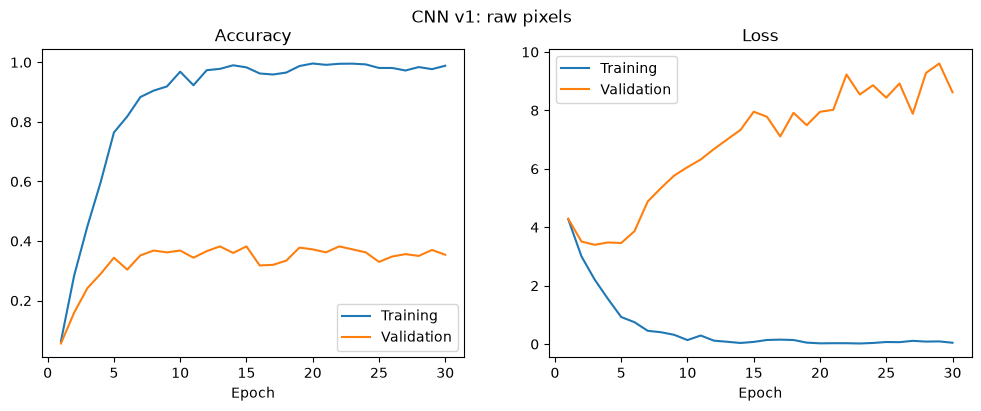

v1: raw pixels
  Train accuracy:      0.45
  Validation accuracy: 0.242
  Test accuracy:       0.248
  Test loss:           3.347


In [209]:
plot_history(history_v1, "CNN v1: raw pixels")
evaluate_model(cnn_v1, "v1: raw pixels")

### CNN v2: add normalization (this is our baseline)

In [212]:
cnn_v2 = nn.Sequential(
    Rescale(),                            # NEW: pixels go from 0-255 to 0-1

    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    
    nn.AdaptiveAvgPool2d((7,7)),
    nn.Flatten(),
    
    nn.Linear(128 * 7 * 7, 128),
    nn.ReLU(),
    nn.Linear(128, num_classes),
)

print(cnn_v2)
print("Parameters to learn:", count_parameters(cnn_v2))

Sequential(
  (0): Rescale()
  (1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): ReLU()
  (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU()
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): AdaptiveAvgPool2d(output_size=(7, 7))
  (11): Flatten(start_dim=1, end_dim=-1)
  (12): Linear(in_features=6272, out_features=128, bias=True)
  (13): ReLU()
  (14): Linear(in_features=128, out_features=100, bias=True)
)
Parameters to learn: 909092


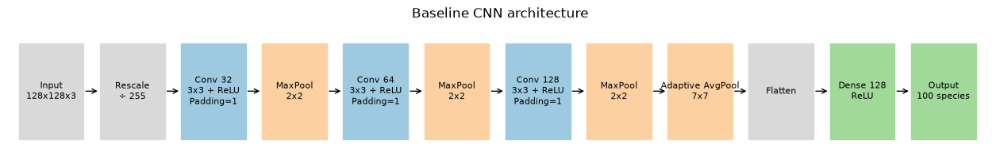

In [213]:
# Simple architecture diagram of the baseline
blue = "#9ecae1"
orange = "#fdd0a2"
green = "#a1d99b"
gray = "#d9d9d9"

blocks = [
    ("Input\n128x128x3", gray),
    ("Rescale\n÷ 255", gray),
    ("Conv 32\n3x3 + ReLU\nPadding=1", blue),
    ("MaxPool\n2x2", orange),
    ("Conv 64\n3x3 + ReLU\nPadding=1", blue),
    ("MaxPool\n2x2", orange),
    ("Conv 128\n3x3 + ReLU\nPadding=1", blue),
    ("MaxPool\n2x2", orange),
    ("Adaptive AvgPool\n7x7", orange),
    ("Flatten", gray),
    ("Dense 128\nReLU", green),
    ("Output\n" + str(num_classes) + " species", green),
]

fig, ax = plt.subplots(figsize=(16, 2.2))

for i, (label, color) in enumerate(blocks):
    x = i * 1.5
    ax.add_patch(plt.Rectangle((x, 0), 1.2, 1, color=color))
    ax.text(x + 0.6, 0.5, label, ha="center", va="center", fontsize=8)
    if i < len(blocks) - 1:
        ax.annotate("", xy=(x + 1.5, 0.5), xytext=(x + 1.2, 0.5),
                    arrowprops=dict(arrowstyle="->"))

ax.set_xlim(-0.2, len(blocks) * 1.5)
ax.set_ylim(-0.2, 1.2)
ax.axis("off")
plt.title("Baseline CNN architecture")
plt.show()

In [214]:
history_v2 = train_model(cnn_v2, "cnn_v2_baseline", train_loader_plain)

Epoch 1 | train loss 4.553 acc 0.02 | val loss 4.563 acc 0.016 | time 7.12 sec
Epoch 2 | train loss 3.958 acc 0.092 | val loss 4.086 acc 0.06 | time 7.12 sec
Epoch 3 | train loss 3.383 acc 0.18 | val loss 3.743 acc 0.098 | time 7.18 sec
Epoch 4 | train loss 2.951 acc 0.258 | val loss 3.563 acc 0.172 | time 7.23 sec
Epoch 5 | train loss 2.57 acc 0.324 | val loss 3.379 acc 0.218 | time 7.1 sec
Epoch 6 | train loss 2.128 acc 0.458 | val loss 3.12 acc 0.262 | time 7.1 sec
Epoch 7 | train loss 1.842 acc 0.526 | val loss 3.119 acc 0.292 | time 7.09 sec
Epoch 8 | train loss 1.501 acc 0.596 | val loss 3.091 acc 0.306 | time 7.09 sec
Epoch 9 | train loss 1.289 acc 0.665 | val loss 3.071 acc 0.358 | time 7.13 sec
Epoch 10 | train loss 1.101 acc 0.692 | val loss 3.264 acc 0.316 | time 7.21 sec
Epoch 11 | train loss 1.011 acc 0.716 | val loss 3.406 acc 0.324 | time 7.06 sec
Epoch 12 | train loss 0.798 acc 0.767 | val loss 3.544 acc 0.342 | time 7.03 sec
Epoch 13 | train loss 0.588 acc 0.828 | val 

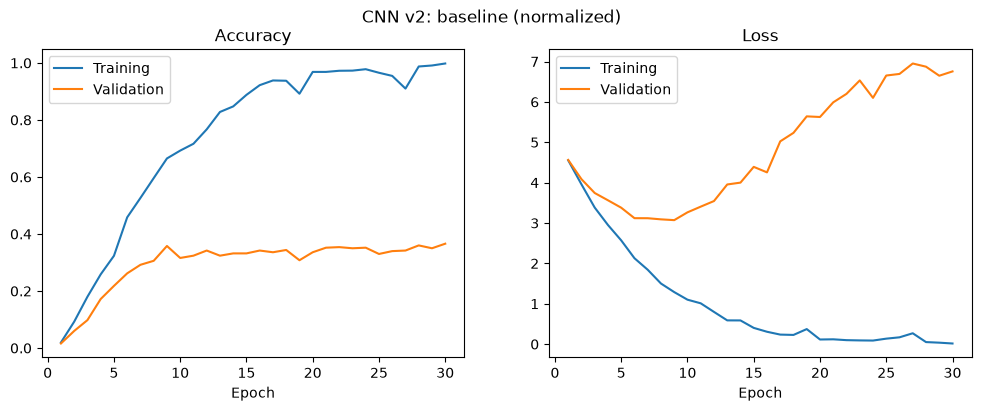

v2: + normalization (baseline)
  Train accuracy:      0.665
  Validation accuracy: 0.358
  Test accuracy:       0.286
  Test loss:           3.302


In [215]:
plot_history(history_v2, "CNN v2: baseline (normalized)")
evaluate_model(cnn_v2, "v2: + normalization (baseline)")

In [216]:
# Classification report for the baseline (on the test set)
_, _, y_true, y_pred = evaluate_loader(cnn_v2, test_loader)

print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

                           precision    recall  f1-score   support

                   ADONIS       0.33      0.60      0.43         5
AFRICAN GIANT SWALLOWTAIL       0.62      1.00      0.77         5
           AMERICAN SNOOT       0.14      0.20      0.17         5
                    AN 88       0.67      0.40      0.50         5
                  APPOLLO       0.09      0.40      0.15         5
     ARCIGERA FLOWER MOTH       0.25      0.40      0.31         5
                    ATALA       0.75      0.60      0.67         5
               ATLAS MOTH       0.38      0.60      0.46         5
 BANDED ORANGE HELICONIAN       0.17      0.20      0.18         5
           BANDED PEACOCK       0.75      0.60      0.67         5
        BANDED TIGER MOTH       0.12      0.20      0.15         5
            BECKERS WHITE       0.00      0.00      0.00         5
  BIRD CHERRY ERMINE MOTH       0.25      0.20      0.22         5
         BLACK HAIRSTREAK       0.13      0.40      0.20     

### CNN v3: add data augmentation

The model is the same as v2. The difference is that we train it with `train_loader_aug`, which randomly flips, rotates and zooms every training image.

In [219]:
cnn_v3 = nn.Sequential(
    Rescale(),

    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    
    nn.AdaptiveAvgPool2d((7,7)),
    nn.Flatten(),
    
    nn.Linear(128 * 7 * 7, 128),
    nn.ReLU(),
    nn.Linear(128, num_classes),
)

print(cnn_v3)
print("Parameters to learn:", count_parameters(cnn_v3))

Sequential(
  (0): Rescale()
  (1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): ReLU()
  (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU()
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): AdaptiveAvgPool2d(output_size=(7, 7))
  (11): Flatten(start_dim=1, end_dim=-1)
  (12): Linear(in_features=6272, out_features=128, bias=True)
  (13): ReLU()
  (14): Linear(in_features=128, out_features=100, bias=True)
)
Parameters to learn: 909092


In [220]:
# NEW: train with the augmented loader
history_v3 = train_model(cnn_v3, "cnn_v3_augmentation", train_loader_aug)

Epoch 1 | train loss 4.606 acc 0.01 | val loss 4.606 acc 0.01 | time 14.5 sec
Epoch 2 | train loss 4.406 acc 0.023 | val loss 4.404 acc 0.022 | time 14.65 sec
Epoch 3 | train loss 4.0 acc 0.063 | val loss 4.057 acc 0.058 | time 14.24 sec
Epoch 4 | train loss 3.639 acc 0.132 | val loss 3.873 acc 0.118 | time 14.4 sec
Epoch 5 | train loss 3.136 acc 0.211 | val loss 3.458 acc 0.174 | time 14.82 sec
Epoch 6 | train loss 3.04 acc 0.252 | val loss 3.408 acc 0.192 | time 14.87 sec
Epoch 7 | train loss 2.685 acc 0.324 | val loss 3.217 acc 0.234 | time 15.13 sec
Epoch 8 | train loss 2.571 acc 0.355 | val loss 3.066 acc 0.278 | time 15.02 sec
Epoch 9 | train loss 2.419 acc 0.388 | val loss 2.946 acc 0.28 | time 15.21 sec
Epoch 10 | train loss 2.318 acc 0.414 | val loss 2.859 acc 0.29 | time 15.29 sec
Epoch 11 | train loss 2.044 acc 0.464 | val loss 2.895 acc 0.326 | time 14.82 sec
Epoch 12 | train loss 1.943 acc 0.494 | val loss 2.76 acc 0.314 | time 14.77 sec
Epoch 13 | train loss 1.724 acc 0.5

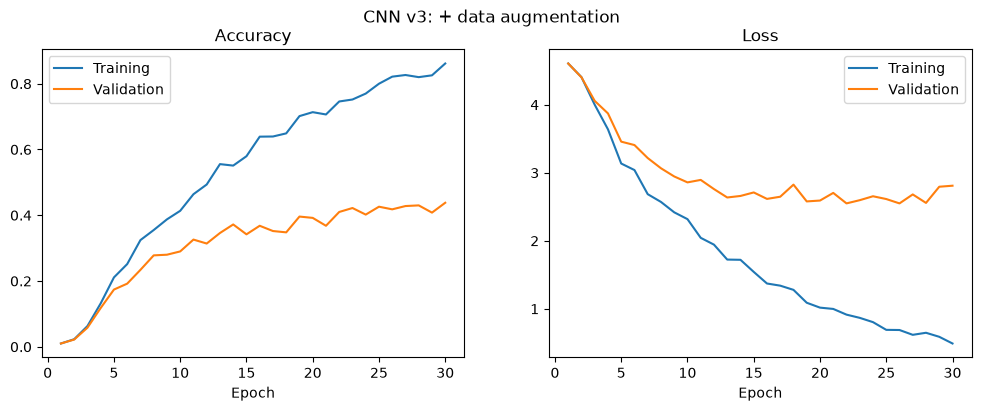

v3: + augmentation
  Train accuracy:      0.822
  Validation accuracy: 0.418
  Test accuracy:       0.424
  Test loss:           2.574


In [221]:
plot_history(history_v3, "CNN v3: + data augmentation")
evaluate_model(cnn_v3, "v3: + augmentation")

### CNN v4: add batch normalization and dropout

In [222]:
cnn_v4 = nn.Sequential(
    Rescale(),

    nn.Conv2d(3, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.BatchNorm2d(32),                   # NEW
    nn.MaxPool2d(2),

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.BatchNorm2d(64),                   # NEW
    nn.MaxPool2d(2),

    nn.Conv2d(64, 128, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.BatchNorm2d(128),                  # NEW
    nn.MaxPool2d(2),
    
    nn.AdaptiveAvgPool2d((7,7)),
    nn.Flatten(),
    
    nn.Linear(128 * 7 * 7, 128),
    nn.ReLU(),
    nn.Dropout(0.5),                      # NEW: randomly switch off half the neurons while training
    nn.Linear(128, num_classes),
)

print(cnn_v4)
print("Parameters to learn:", count_parameters(cnn_v4))

Sequential(
  (0): Rescale()
  (1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (2): ReLU()
  (3): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU()
  (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (10): ReLU()
  (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (13): AdaptiveAvgPool2d(output_size=(7, 7))
  (14): Flatten(start_dim=1, end_dim=-1)
  (15): Linear(in_features=6272, out_features=128, bias=True)
  (16): ReLU()
  

In [223]:
history_v4 = train_model(cnn_v4, "cnn_v4_batchnorm_dropout", train_loader_aug)

Epoch 1 | train loss 4.285 acc 0.074 | val loss 4.36 acc 0.058 | time 18.55 sec
Epoch 2 | train loss 3.667 acc 0.16 | val loss 3.931 acc 0.128 | time 16.55 sec
Epoch 3 | train loss 3.261 acc 0.228 | val loss 3.609 acc 0.178 | time 16.64 sec
Epoch 4 | train loss 2.834 acc 0.322 | val loss 3.243 acc 0.232 | time 17.49 sec
Epoch 5 | train loss 2.682 acc 0.345 | val loss 3.194 acc 0.256 | time 16.5 sec
Epoch 6 | train loss 2.29 acc 0.422 | val loss 2.956 acc 0.302 | time 16.66 sec
Epoch 7 | train loss 2.055 acc 0.476 | val loss 2.613 acc 0.33 | time 16.49 sec
Epoch 8 | train loss 1.857 acc 0.526 | val loss 2.626 acc 0.348 | time 16.45 sec
Epoch 9 | train loss 1.669 acc 0.574 | val loss 2.49 acc 0.39 | time 16.49 sec
Epoch 10 | train loss 1.481 acc 0.627 | val loss 2.241 acc 0.416 | time 17.22 sec
Epoch 11 | train loss 1.414 acc 0.625 | val loss 2.35 acc 0.426 | time 17.6 sec
Epoch 12 | train loss 1.312 acc 0.642 | val loss 2.26 acc 0.428 | time 17.18 sec
Epoch 13 | train loss 1.301 acc 0.6

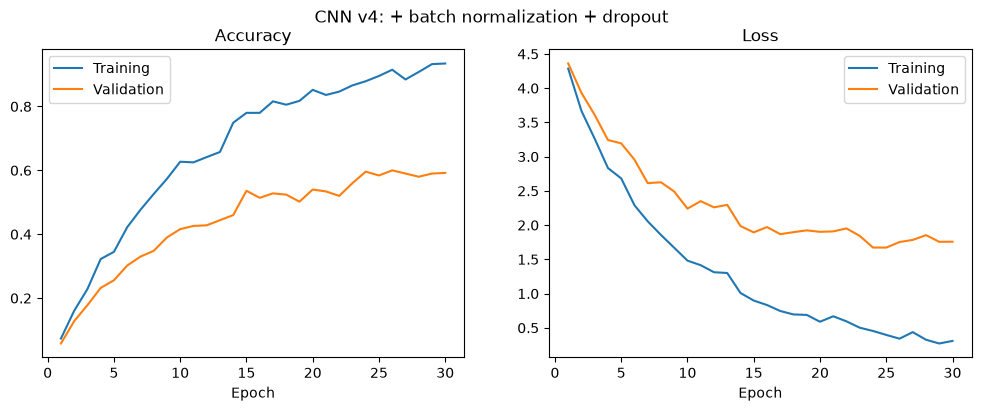

v4: + batch norm + dropout
  Train accuracy:      0.896
  Validation accuracy: 0.584
  Test accuracy:       0.602
  Test loss:           1.553


In [224]:
plot_history(history_v4, "CNN v4: + batch normalization + dropout")
evaluate_model(cnn_v4, "v4: + batch norm + dropout")

### CNN trials: test learning rate and batch size effects

In [239]:
# best CNN architecture
tune_model = cnn_v4

# Use augmentation 
use_augmentation = True

learning_rates = [0.001, 0.0003, 0.0001]
batch_sizes = [16, 32, 64]

results = []

In [245]:
import copy

for batch_size in batch_sizes:

    # Recreate loaders for this batch size
    if use_augmentation:
        train_dataset = ImageData(train_images, train_labels, augmentation)
    else:
        train_dataset = ImageData(train_images, train_labels)

    train_loader = DataLoader(train_dataset, batch_size, shuffle=True)

    # Clean training data for evaluation
    train_loader_eval = DataLoader(ImageData(train_images, train_labels),
                                   batch_size=batch_size, shuffle=False)

    # Clean validation data
    val_loader = DataLoader(ImageData(val_images, val_labels),
                            batch_size=batch_size, shuffle=False)

    for lr in learning_rates:

        print(f"\nTesting batch size = {batch_size}, learning rate = {lr}")

        # Fresh copy of the same starting model
        model = copy.deepcopy(tune_model)

        # Give every experiment its own checkpoint name
        name = f"cnn4_lr{lr}_bs{batch_size}"

        # Train
        history = train_model(model, name=name, train_loader=train_loader, epochs=30)

        # Find the epoch with the lowest validation loss
        best_epoch = history["val_loss"].index(min(history["val_loss"]))

        results.append({                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   
            "batch_size": batch_size,
            "learning_rate": lr,
            "best_epoch": best_epoch + 1,
            "best_val_loss": history["val_loss"][best_epoch],
            "best_val_accuracy": history["val_accuracy"][best_epoch],
            "training_time_min": history["training_time_min"]
        })


Testing batch size = 16, learning rate = 0.001
Epoch 1 | train loss 0.487 acc 0.87 | val loss 1.934 acc 0.564 | time 18.52 sec
Epoch 2 | train loss 0.426 acc 0.892 | val loss 1.833 acc 0.588 | time 18.08 sec
Epoch 3 | train loss 0.436 acc 0.898 | val loss 1.717 acc 0.6 | time 17.5 sec
Epoch 4 | train loss 0.529 acc 0.856 | val loss 2.076 acc 0.544 | time 17.43 sec
Epoch 5 | train loss 0.312 acc 0.912 | val loss 1.851 acc 0.572 | time 17.55 sec
Epoch 6 | train loss 0.431 acc 0.88 | val loss 1.941 acc 0.576 | time 17.28 sec
Epoch 7 | train loss 0.25 acc 0.932 | val loss 1.839 acc 0.6 | time 17.5 sec
Epoch 8 | train loss 0.22 acc 0.948 | val loss 1.75 acc 0.614 | time 17.02 sec
Epoch 9 | train loss 0.243 acc 0.94 | val loss 1.838 acc 0.628 | time 17.68 sec
Epoch 10 | train loss 0.223 acc 0.942 | val loss 1.812 acc 0.608 | time 17.22 sec
Epoch 11 | train loss 0.222 acc 0.942 | val loss 1.863 acc 0.604 | time 17.19 sec
Epoch 12 | train loss 0.179 acc 0.954 | val loss 1.968 acc 0.626 | time

## 8. Compare the whole CNN ladder

In [301]:
#CNN architecture comparison

trained_model_files = {
    "CNN1": "cnn_v1_raw_pixels",
    "CNN2": "cnn_v2_baseline",
    "CNN3": "cnn_v3_augmentation",
    "CNN4": "cnn_v4_batchnorm_dropout"}

comparison = []

for model_name, file_name in trained_model_files.items():

    history_file = os.path.join("checkpoints", file_name + "_history.json")

    with open(history_file, "r") as file:
        history = json.load(file)

    best_epoch = history["val_loss"].index(min(history["val_loss"]))

    train_acc = history["accuracy"][best_epoch]
    val_acc = history["val_accuracy"][best_epoch]

    comparison.append({"model": model_name,
                       "best_epoch": best_epoch + 1,
                       "train_accuracy": train_acc,
                       "val_accuracy": val_acc,
                       "train_minus_val": train_acc - val_acc,
                       "val_loss": history["val_loss"][best_epoch],
                       "training_time_min": history.get("training_time_min") })

cnn_comparison = pd.DataFrame(comparison).round(3)

display(cnn_comparison)

,model,best_epoch,train_accuracy,val_accuracy,train_minus_val,val_loss,training_time_min
0,CNN1,3,0.450,0.242,0.208,3.399,3.54
1,CNN2,9,0.665,0.358,0.307,3.071,3.55
2,CNN3,26,0.822,0.418,0.404,2.550,7.42
3,CNN4,25,0.896,0.584,0.312,1.672,8.48


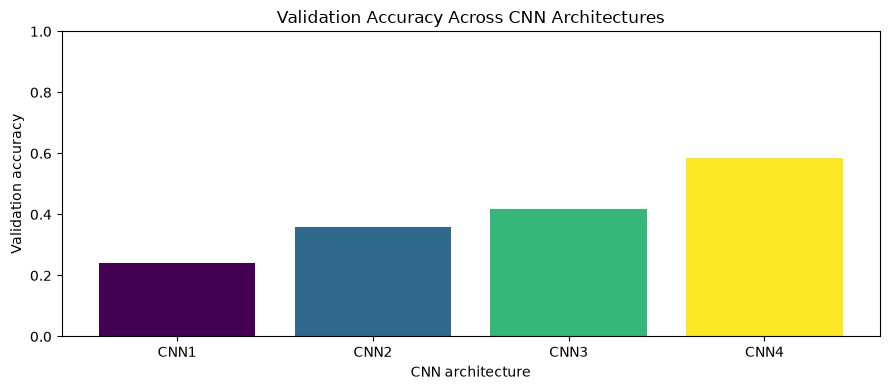

In [351]:
#bar chart - accuracy at each step of the ladder
colors = plt.cm.viridis(np.linspace(0, 1, len(cnn_comparison)))
plt.figure(figsize=(9, 4))
plt.bar(cnn_comparison["model"], cnn_comparison["val_accuracy"], color=colors)
plt.ylabel("Validation accuracy")
plt.xlabel("CNN architecture")
plt.title("Validation Accuracy Across CNN Architectures")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [303]:
#compare cn tuning results
tuning_table = pd.DataFrame(results)

tuning_table["model"] = "CNN4"

tuning_table = tuning_table[["model", "batch_size", "learning_rate", "best_epoch",
        "best_val_loss", "best_val_accuracy", "training_time_min"]].round(3)

display(tuning_table.sort_values("best_val_accuracy", ascending=False))

,model,batch_size,learning_rate,best_epoch,best_val_loss,best_val_accuracy,training_time_min
2,CNN4,16,0.000,23,1.459,0.702,8.40
0,CNN4,16,0.001,28,1.490,0.698,8.67
4,CNN4,32,0.000,28,1.508,0.696,8.32
3,CNN4,32,0.001,28,1.474,0.676,8.15
7,CNN4,64,0.000,28,1.498,0.676,9.16
8,CNN4,64,0.000,21,1.528,0.670,10.44
6,CNN4,64,0.001,17,1.456,0.664,8.51
1,CNN4,16,0.000,15,1.572,0.646,8.62
5,CNN4,32,0.000,24,1.537,0.642,8.57


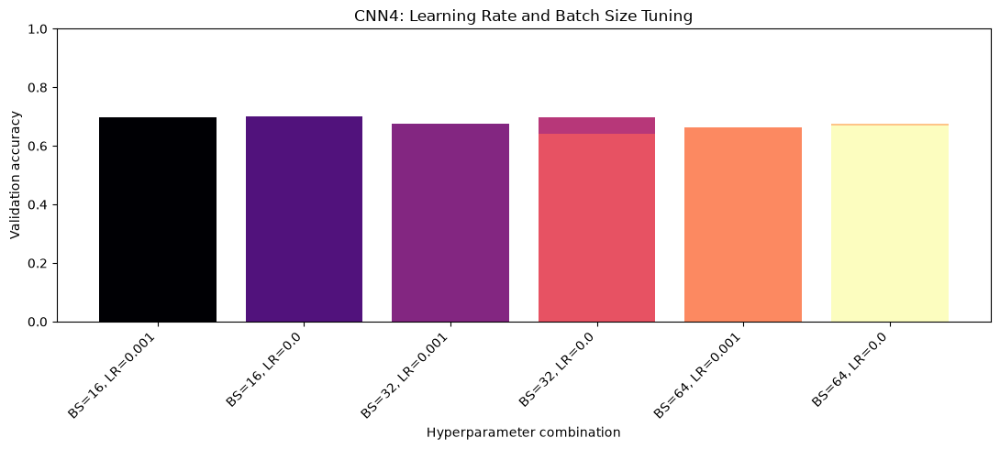

In [364]:
#bar chart to visualize tuning effects
colors = plt.cm.magma(np.linspace(0, 1, len(tuning_table)))
tuning_table["experiment"] = ("BS=" + tuning_table["batch_size"].astype(str)
                              + ", LR=" + tuning_table["learning_rate"].astype(str))

plt.figure(figsize=(11, 5))

plt.bar(tuning_table["experiment"], tuning_table["best_val_accuracy"], color=colors)

plt.xticks(rotation=45, ha="right")
plt.ylabel("Validation accuracy")
plt.xlabel("Hyperparameter combination")
plt.title("CNN4: Learning Rate and Batch Size Tuning")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

## 9. Best CNN: classification report and confusion matrix

In [318]:
#Pick CNN with best validation score
best_row = tuning_table.loc[tuning_table["best_val_accuracy"].idxmax()]

best_name = (f"cnn4_lr{best_row['learning_rate']}_bs{int(best_row['batch_size'])}")

print("Best CNN4 experiment:", best_name)
print("Best validation accuracy:", best_row["best_val_accuracy"])

Best CNN4 experiment: cnn4_lr0.0_bs16
Best validation accuracy: 0.702


In [320]:
# Load best model's saved checkpoint
best_cnn = copy.deepcopy(cnn_v4)
best_weights = os.path.join("checkpoints", best_name + ".pt")
best_cnn.to(device)
best_cnn.eval()
print("Best CNN:", best_name)

#Classification report on test set
_, _, y_true, y_pred = evaluate_loader(best_cnn, test_loader)
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

Best CNN: cnn4_lr0.0_bs16
                           precision    recall  f1-score   support

                   ADONIS       0.50      0.80      0.62         5
AFRICAN GIANT SWALLOWTAIL       1.00      1.00      1.00         5
           AMERICAN SNOOT       0.25      0.20      0.22         5
                    AN 88       1.00      0.80      0.89         5
                  APPOLLO       0.29      0.40      0.33         5
     ARCIGERA FLOWER MOTH       1.00      0.60      0.75         5
                    ATALA       0.43      0.60      0.50         5
               ATLAS MOTH       1.00      0.60      0.75         5
 BANDED ORANGE HELICONIAN       1.00      0.60      0.75         5
           BANDED PEACOCK       1.00      1.00      1.00         5
        BANDED TIGER MOTH       1.00      0.40      0.57         5
            BECKERS WHITE       0.00      0.00      0.00         5
  BIRD CHERRY ERMINE MOTH       0.43      0.60      0.50         5
         BLACK HAIRSTREAK       0.8

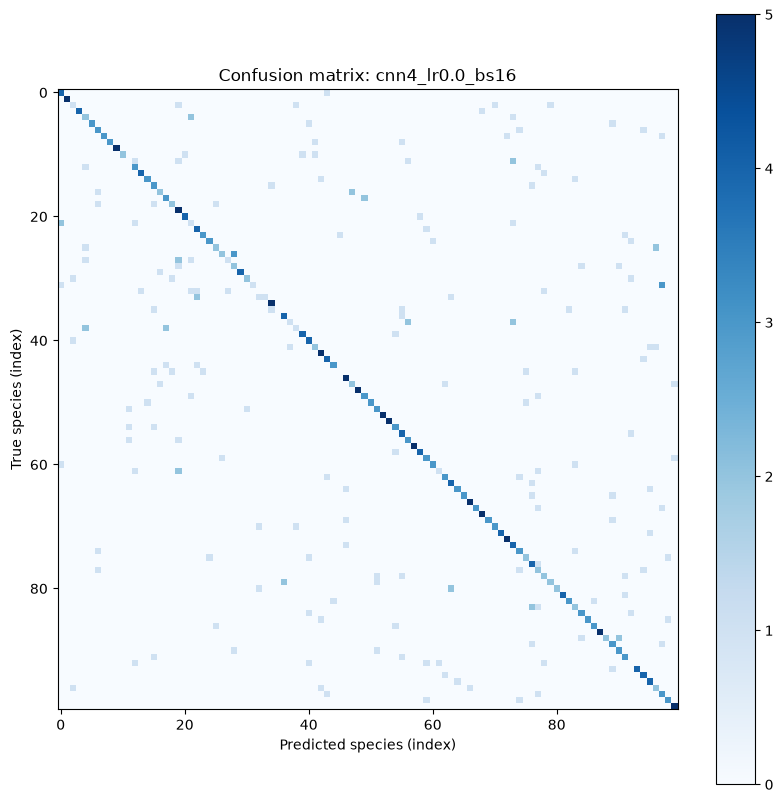

In [331]:
# Confusion matrix (100 x 100, so it is hard to read, but the diagonal line shows correct guesses)
cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))

plt.figure(figsize=(10, 10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.title("Confusion matrix: " + best_name)
plt.xlabel("Predicted species (index)")
plt.ylabel("True species (index)")
plt.show()

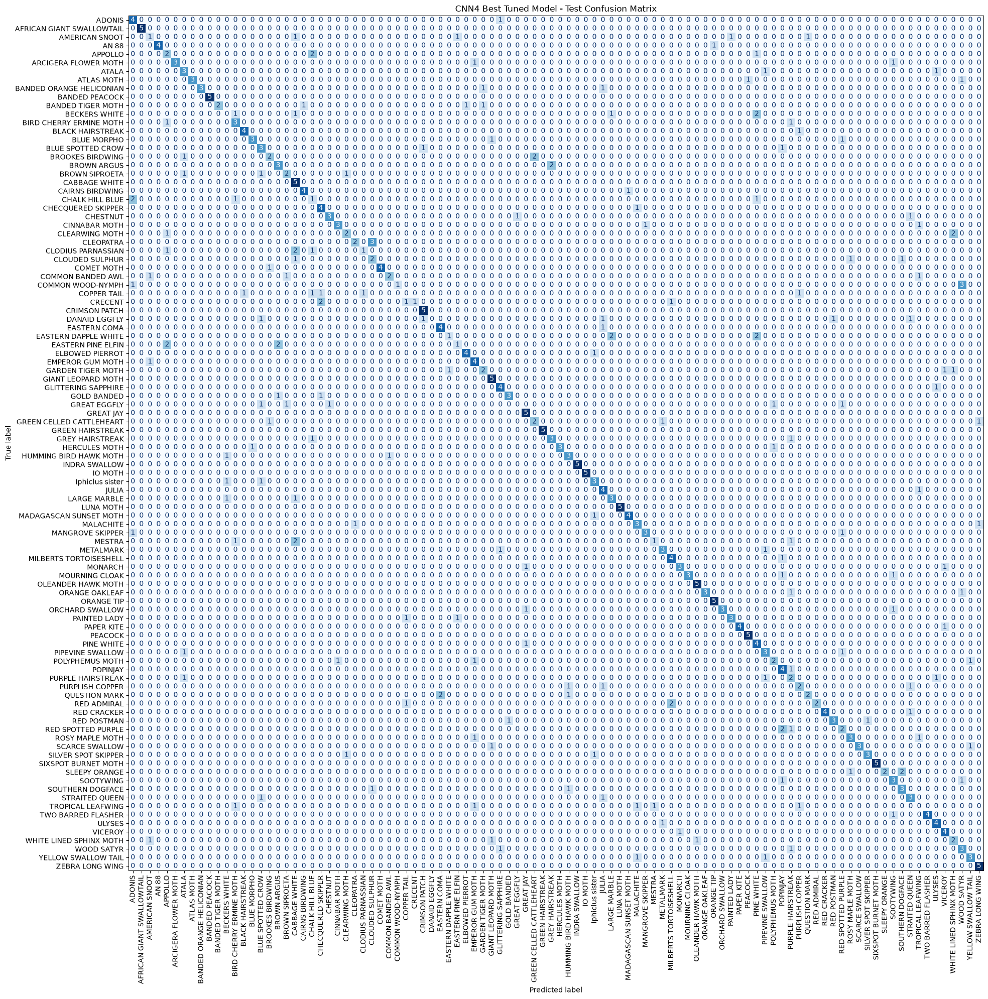

In [329]:
#Confusion matrix
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(20, 20))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=90, colorbar=False)

plt.title("CNN4 Best Tuned Model - Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [341]:
# Which pairs of species get mixed up the most?
confused_pairs = []

for true_index in range(num_classes):
    for predicted_index in range(num_classes):
        if true_index != predicted_index and cm[true_index][predicted_index] > 0:
            confused_pairs.append((cm[true_index][predicted_index], class_names[true_index], class_names[predicted_index]))

confused_pairs.sort(reverse=True)

print("Most common mistakes (times, true species, predicted species):")
for count, true_name, predicted_name in confused_pairs[:10]:
    print(count, "|", true_name, "->", predicted_name)

Most common mistakes (times, true species, predicted species):
3 | COMMON WOOD-NYMPH -> WOOD SATYR
3 | CLEOPATRA -> CLOUDED SULPHUR
2 | SLEEPY ORANGE -> SOUTHERN DOGFACE
2 | RED SPOTTED PURPLE -> POPINJAY
2 | RED ADMIRAL -> MILBERTS TORTOISESHELL
2 | QUESTION MARK -> EASTERN COMA
2 | MESTRA -> CABBAGE WHITE
2 | EASTERN PINE ELFIN -> BROWN ARGUS
2 | EASTERN PINE ELFIN -> APPOLLO
2 | EASTERN DAPPLE WHITE -> PINE WHITE


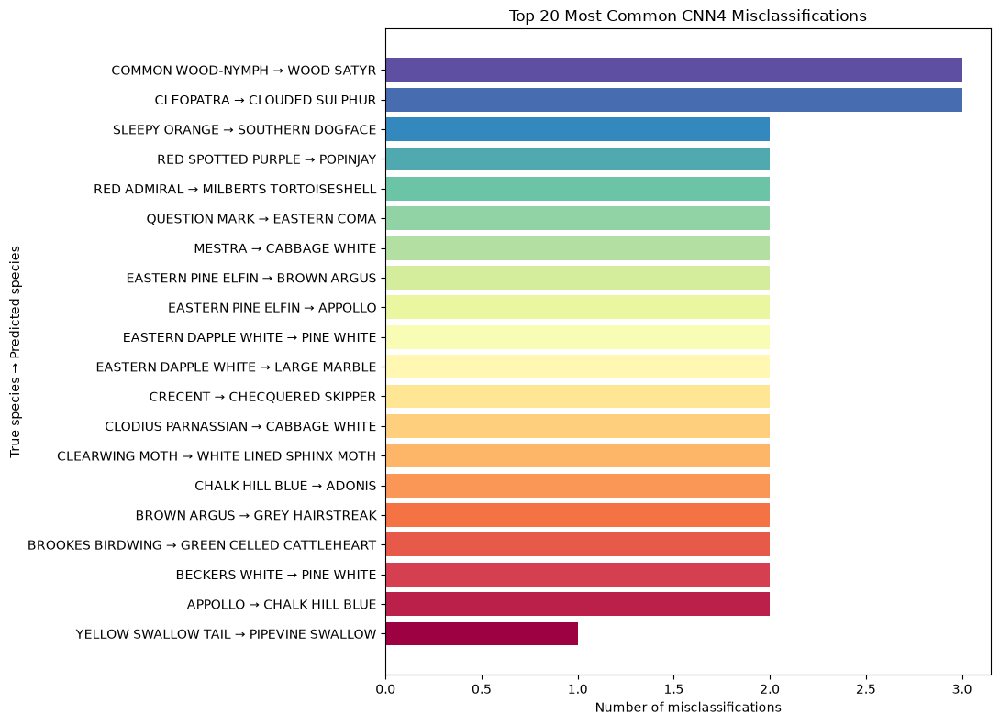

In [366]:
#Plot top 20 mistakes
top_20 = confused_pairs[:20]
labels = [f"{true_name} → {predicted_name}" for count, true_name, predicted_name in top_20]
counts = [count for count, _, _ in top_20]
colors = plt.cm.Spectral(np.linspace(0, 1, len(top_20)))
plt.figure(figsize=(11, 8))
plt.barh(labels[::-1], counts[::-1], color=colors)
plt.xlabel("Number of misclassifications")
plt.ylabel("True species → Predicted species")
plt.title("Top 20 Most Common CNN4 Misclassifications")
plt.tight_layout()
plt.show()